# Pediatric Psychiatric Readmission — PyHealth EHR Coding & Advanced Statistical Modeling

This notebook extends `Readmission_Full_Analysis.ipynb` with two additions requested for the GD1854RVSD pediatric psychiatric rehospitalization cohort (Arizona, 2016–2021; one row per patient, *N* ≈ 2,652, ~9.3% readmitted):

**Part A — Shared modeling foundation.** Re-loads the cohort, applies the same date-quality filter and feature engineering as the main analysis, and refits the three reference models (Logistic Regression + interactions, Random Forest, CatBoost) with 10-fold *out-of-fold* (OOF) predictions. All advanced statistics below operate on these OOF predictions.

**Part B — PyHealth EHR coding utilities (no deep nets).** Uses `pyhealth.medcode` (ICD-10-CM `InnerMap` and the ICD-10-CM → CCS `CrossMap`) to (1) *validate* the cohort's raw ICD-10 codes against the official coding system, (2) recover official descriptions for the many `[description unavailable]` placeholders in the source data, and (3) roll codes up into standardized **Clinical Classifications Software (CCS)** comorbidity groups — a recognized, reproducible grouping that complements the hand-built DSM-5 flags. The data are single-visit code *sets*, so PyHealth is used here for principled medical-code standardization rather than sequential deep models.

**Part C — Advanced statistical modeling.**
1. **Bootstrap 95% CIs** for AUC-ROC and AUC-PR (overall and by subgroup).
2. **Calibration metrics + recalibration**: Brier score, Expected Calibration Error (ECE), Hosmer–Lemeshow; Platt (sigmoid) and isotonic recalibration with cross-validation, reported before vs. after.
3. **Formal fairness / equity metrics**: subgroup AUC with CIs, calibration-in-the-group, FPR/FNR/PPV at a fixed operating threshold, equalized-odds gaps, and demographic-parity differences across sex, insurance, age, and ACE strata.
4. **Optimism-corrected validation**: bootstrap (.632) optimism correction for the logistic model and nested cross-validation for the ML models, contrasted with the naive estimates.

> **Note on small positive count.** With only ~246 readmissions, optimism-corrected and nested estimates are expected to be *lower* than the naive resubstitution/OOF numbers — that honesty is the point of Part C4.

## Part A — Shared modeling foundation

Loads the cohort, applies the same data-quality filter and feature engineering as the main analysis, and refits the three reference models with 10-fold out-of-fold predictions.

In [1]:
# ── Imports & global settings ─────────────────────────────────────────────────
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')

# Poster-quality settings (consistent with main analysis)
plt.rcParams.update({
    'font.size': 13, 'axes.titlesize': 15, 'axes.labelsize': 13,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 130, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
sns.set_style('whitegrid')
BLUE, ORANGE = '#4C72B0', '#DD8452'
MODEL_COLORS = {'Logistic Regression': '#2166ac', 'Random Forest': '#4dac26', 'CatBoost': '#d01c8b'}

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

os.makedirs('figures', exist_ok=True)
DATA_FILE = 'annotated_psychiatric_data_complete.csv'
print('✓ Libraries loaded. Figures → ./figures/  | data file:', DATA_FILE)

✓ Libraries loaded. Figures → ./figures/  | data file: annotated_psychiatric_data_complete.csv


In [2]:
# ── Load data & feature engineering (mirrors Readmission_Full_Analysis.ipynb) ──
df = pd.read_csv(DATA_FILE)

# ── Outcome ──────────────────────────────────────────────────────────────────
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate'] = pd.to_datetime(df['DischDate'], errors='coerce')
df['los_days']  = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER (same exclusions as main analysis) ───────────────────
flag_missing_visit = df['VisitDate'].isna()
flag_missing_disch = df['DischDate'].isna()
flag_negative_los  = df['los_days'].notna() & (df['los_days'] < 0)
bad = flag_missing_visit | flag_missing_disch | flag_negative_los
print(f"Date-quality exclusions: {int(bad.sum())} records "
      f"(missing visit={int(flag_missing_visit.sum())}, missing disch={int(flag_missing_disch.sum())}, "
      f"negative LOS={int(flag_negative_los.sum())})")
df = df[~bad].copy().reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '':
        return 0
    return len([x for x in str(s).split(',') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags ──────────────────────────────────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()
CATEGORY_FLAGS = {
    'has_nssi': 'non-suicidal self-injury', 'has_trauma': 'trauma and stressor',
    'has_adhd': 'adhd', 'has_asd': 'autism spectrum', 'has_conduct': 'conduct disorder',
    'has_depression': 'depressive disorders', 'has_anxiety': 'anxiety disorders',
    'has_bipolar': 'bipolar', 'has_psychotic': 'psychotic',
    'has_intellectual': 'intellectual disability', 'has_ocd': 'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)

# ── Medical comorbidity ───────────────────────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '':
        return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
df['has_medical_comorbidity'] = (df['n_medical_chronic'] > 0).astype(int)

print(f"✓ Feature engineering complete. N = {len(df):,} | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")

Date-quality exclusions: 0 records (missing visit=0, missing disch=0, negative LOS=0)
✓ Feature engineering complete. N = 2,652 | Readmitted = 246 (9.3%)


In [3]:
# ── Build feature matrix + interactions, fit 3 models with 10-fold OOF preds ───
FEATURES = {
    'age': 'Age at Admission', 'gender_male': 'Male Sex',
    'insurance_public': 'Public Insurance (AHCCCS)', 'ace_score': 'ACE Score',
    'had_restraints': 'Physical Restraints', 'csrss_any': 'Any C-SSRS Flag',
    'los_days': 'Length of Stay (days)', 'n_dsm5_categories': '# DSM-5 Categories',
    'has_medical_comorbidity': 'Medical Comorbidity', 'has_nssi': 'NSSI Diagnosis',
    'has_trauma': 'Trauma/PTSD', 'has_adhd': 'ADHD', 'has_asd': 'ASD',
    'has_conduct': 'Conduct Disorder', 'has_depression': 'Depression',
    'has_anxiety': 'Anxiety', 'has_bipolar': 'Bipolar Disorder',
    'has_psychotic': 'Psychotic Disorder',
}
feat_cols = list(FEATURES.keys())
model_df = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow']].copy()

# Median imputation (ACE ~30% missing; documented in methods of main analysis)
model_df['ace_score'] = model_df['ace_score'].fillna(model_df['ace_score'].median())
model_df['los_days']  = model_df['los_days'].fillna(model_df['los_days'].median())
model_df = model_df.dropna().reset_index(drop=True)

# Clinically motivated interaction terms
model_df['age_x_conduct']        = model_df['age'] * model_df['has_conduct']
model_df['age_x_asd']            = model_df['age'] * model_df['has_asd']
model_df['ace_x_trauma']         = model_df['ace_score'] * model_df['has_trauma']
model_df['complexity_x_age']     = model_df['n_dsm5_categories'] * model_df['age']
model_df['csrss_level']          = (model_df['csrss_red'] * 3 + model_df['csrss_orange'] * 2
                                    + model_df['csrss_yellow'] * 1).fillna(0).astype(int)
model_df['nssi_x_csrss_red']     = model_df['has_nssi'] * model_df['csrss_red']
model_df['age_x_public_insurance'] = model_df['age'] * model_df['insurance_public']

# Keep an UNSCALED copy so subgroup thresholds (e.g. age<=9, ACE>=4) use real units
model_df_unscaled = model_df.copy()

interaction_keys = ['age_x_conduct', 'age_x_asd', 'ace_x_trauma',
                    'nssi_x_csrss_red', 'complexity_x_age', 'age_x_public_insurance']
all_x_cols = [c for c in feat_cols if c != 'csrss_any'] + interaction_keys + ['csrss_level']

# Standardize continuous predictors for OR interpretability
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories', 'complexity_x_age']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

X_ml = model_df[all_x_cols].values
y_ml = model_df['readmitted'].values
print(f"Model dataset: {len(model_df):,} patients | {int(y_ml.sum())} readmitted "
      f"({y_ml.mean():.1%}) | {len(all_x_cols)} predictors")

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RNG_SEED)

# ── Random Forest (10-fold OOF) ───────────────────────────────────────────────
rf = RandomForestClassifier(n_estimators=500, max_depth=6, min_samples_leaf=10,
                            class_weight='balanced', random_state=RNG_SEED, n_jobs=-1)
rf_probs = np.zeros(len(y_ml))
for tr, te in cv.split(X_ml, y_ml):
    rf.fit(X_ml[tr], y_ml[tr]); rf_probs[te] = rf.predict_proba(X_ml[te])[:, 1]

# ── CatBoost (10-fold OOF) ────────────────────────────────────────────────────
def make_cat():
    return CatBoostClassifier(iterations=500, depth=4, learning_rate=0.05,
                              auto_class_weights='Balanced', eval_metric='AUC',
                              random_seed=RNG_SEED, verbose=0)
cat_probs = np.zeros(len(y_ml))
for tr, te in cv.split(X_ml, y_ml):
    m = make_cat(); m.fit(X_ml[tr], y_ml[tr]); cat_probs[te] = m.predict_proba(X_ml[te])[:, 1]

# ── Logistic Regression (10-fold OOF) ─────────────────────────────────────────
lr_probs = np.zeros(len(y_ml))
for tr, te in cv.split(X_ml, y_ml):
    Xtr = sm.add_constant(X_ml[tr], has_constant='add')
    Xte = sm.add_constant(X_ml[te], has_constant='add')
    mlr = sm.Logit(y_ml[tr], Xtr).fit(disp=0, maxiter=200)
    lr_probs[te] = mlr.predict(Xte)

# Registry of model OOF predictions used by all Part C analyses
MODELS = {'Logistic Regression': lr_probs, 'Random Forest': rf_probs, 'CatBoost': cat_probs}
for name, p in MODELS.items():
    print(f"{name:<22} AUC={roc_auc_score(y_ml, p):.3f}  AP={average_precision_score(y_ml, p):.3f}")

Model dataset: 2,652 patients | 246 readmitted (9.3%) | 24 predictors
Logistic Regression    AUC=0.667  AP=0.162
Random Forest          AUC=0.686  AP=0.171
CatBoost               AUC=0.662  AP=0.164


## Part B — PyHealth EHR coding utilities

The cohort stores diagnoses as raw ICD-10-CM code *sets* per patient (`VisitDiags`, `ChronicDiags`, `NonSuicidialDiags`). Here we use **`pyhealth.medcode`** to:

1. **Validate** every distinct code against the official ICD-10-CM vocabulary and recover official descriptions (the source file contains many `[description unavailable]` placeholders).
2. **Group** codes into standardized **Clinical Classifications Software (CCS)** categories via the ICD-10-CM → CCS `CrossMap` — a recognized, reproducible grouping that does not depend on our hand-curated DSM-5 map.
3. **Derive patient-level CCS comorbidity features** and compare them against the hand-built DSM-5 flags, including univariate readmission associations.

PyHealth resource files download on first use and are cached locally; a fallback to the repo's `comprehensive_icd_ref.pkl` / `icd_descriptions_full.json` is used if the download is unavailable.

In [4]:
# ── B1: Collect cohort ICD-10 codes & validate against PyHealth ICD-10-CM ──────
DIAG_COLS = ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']

def parse_codes(s):
    """Split a comma-separated ICD code cell into cleaned tokens."""
    if pd.isna(s) or str(s).strip() == '':
        return []
    return [c.strip().upper() for c in str(s).split(',') if c.strip()]

# Per-patient code sets (union across the three diagnosis columns)
patient_codes = df.apply(lambda r: sorted({c for col in DIAG_COLS for c in parse_codes(r.get(col))}), axis=1)
all_codes = sorted({c for codes in patient_codes for c in codes})
print(f"Distinct ICD-10 codes in cohort: {len(all_codes):,}")

# ── Load PyHealth ICD-10-CM InnerMap (with local fallback) ────────────────────
USE_PYHEALTH = True
icd = None
try:
    from pyhealth.medcode import InnerMap, CrossMap
    icd = InnerMap.load('ICD10CM')
    print('✓ PyHealth ICD10CM InnerMap loaded.')
except Exception as e:
    USE_PYHEALTH = False
    print(f'⚠ PyHealth unavailable ({e}); falling back to local reference files.')

# Local fallback description map (used only if PyHealth fails)
local_desc = {}
try:
    import json
    with open('icd_descriptions_full.json') as fh:
        local_desc = {k.strip().upper(): v for k, v in json.load(fh).items()}
except Exception:
    pass

def pyhealth_lookup(code):
    """Return (is_valid, official_description). Tries dotted + dot-inserted variants."""
    if icd is None:
        return (code in local_desc, local_desc.get(code, ''))
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            return True, icd.lookup(v)
        except Exception:
            continue
    return False, ''

valid_flags, descriptions = {}, {}
for c in all_codes:
    ok, desc = pyhealth_lookup(c)
    valid_flags[c] = ok
    descriptions[c] = desc

n_valid = sum(valid_flags.values())
print(f"Valid ICD-10-CM codes: {n_valid:,}/{len(all_codes):,} ({n_valid/len(all_codes):.1%})")

recon = pd.DataFrame({
    'icd_code': all_codes,
    'valid_icd10cm': [valid_flags[c] for c in all_codes],
    'pyhealth_description': [descriptions[c] for c in all_codes],
})
recon['n_patients'] = [int(sum(c in s for s in patient_codes)) for c in all_codes]
recon = recon.sort_values('n_patients', ascending=False).reset_index(drop=True)
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)
print('✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv')
print('\nTop invalid / unmapped codes (by patient count):')
print(recon[~recon['valid_icd10cm']].head(10)[['icd_code', 'n_patients']].to_string(index=False))

Distinct ICD-10 codes in cohort: 1,863
✓ PyHealth ICD10CM InnerMap loaded.
Valid ICD-10-CM codes: 1,843/1,863 (98.9%)
✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv

Top invalid / unmapped codes (by patient count):
icd_code  n_patients
 E88.819           4
 E66.812           3
  F43.89           3
   G90.A           3
 Z91.148           2
 F50.029           2
 Z62.831           1
  R09.A2           1
 Z91.199           1
 Z79.631           1


In [5]:
# ── B2: Map ICD-10 codes to standardized CCS categories (PyHealth CrossMap) ────
ccs_map, ccs_labels = None, None
if USE_PYHEALTH:
    try:
        ccs_map = CrossMap.load('ICD10CM', 'CCSCM')
        ccs_labels = InnerMap.load('CCSCM')
        print('✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.')
    except Exception as e:
        print(f'⚠ CCS mapping unavailable ({e}); CCS features will be skipped.')

def code_to_ccs(code):
    """Map one ICD-10-CM code to (ccs_code, ccs_label) or (None, None)."""
    if ccs_map is None:
        return (None, None)
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            mapped = ccs_map.map(v)
        except Exception:
            mapped = []
        if mapped:
            cc = mapped[0]
            try:
                lab = ccs_labels.lookup(cc)
            except Exception:
                lab = cc
            return (cc, lab)
    return (None, None)

code2ccs = {c: code_to_ccs(c) for c in all_codes}
n_ccs_mapped = sum(1 for v in code2ccs.values() if v[0] is not None)
print(f"Codes mapped to a CCS category: {n_ccs_mapped:,}/{len(all_codes):,} "
      f"({n_ccs_mapped/len(all_codes):.1%})")

# Attach CCS columns to the reconciliation table
recon['ccs_code']  = recon['icd_code'].map(lambda c: code2ccs[c][0])
recon['ccs_label'] = recon['icd_code'].map(lambda c: code2ccs[c][1])
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)

# Cohort-level CCS prevalence (patient-weighted)
ccs_patient_counts = {}
for codes in patient_codes:
    cats = {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for cat in cats:
        ccs_patient_counts[cat] = ccs_patient_counts.get(cat, 0) + 1

ccs_prev = (pd.Series(ccs_patient_counts).sort_values(ascending=False)
            .rename('n_patients').to_frame())
ccs_prev['pct_patients'] = (ccs_prev['n_patients'] / len(df) * 100).round(1)
print(f"\nDistinct CCS categories present in cohort: {len(ccs_prev)}")
print('\nTop 15 CCS categories by patient prevalence:')
print(ccs_prev.head(15).to_string())

✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.
Codes mapped to a CCS category: 1,719/1,863 (92.3%)

Distinct CCS categories present in cohort: 174

Top 15 CCS categories by patient prevalence:
                                                       n_patients  pct_patients
Mood disorders                                               1827          68.9
Anxiety disorders                                            1700          64.1
"Attention-deficit                                           1637          61.7
Suicide and intentional self-inflicted injury                1428          53.8
"Disorders usually diagnosed in infancy                       843          31.8
Administrative/social admission                               832          31.4
Adjustment disorders                                          746          28.1
Residual codes; unclassified                                  653          24.6
Other nutritional; endocrine; and metabolic disorders         402          

In [6]:
# ── B3: Build patient-level CCS comorbidity features ──────────────────────────
TOP_K_CCS = 15
top_ccs = list(ccs_prev.head(TOP_K_CCS).index) if len(ccs_prev) else []

# Per-patient set of CCS categories (aligned with df)
patient_ccs_sets = [
    {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for codes in patient_codes
]

ccs_features = pd.DataFrame(index=df.index)
ccs_features['readmitted'] = df['readmitted'].values
# Standardized comorbidity complexity = # distinct CCS categories
ccs_features['n_ccs_categories'] = [len(s) for s in patient_ccs_sets]

def ccs_colname(label):
    slug = ''.join(ch if ch.isalnum() else '_' for ch in str(label).lower())
    return 'ccs__' + slug[:40].strip('_')

ccs_feature_cols = []
for cat in top_ccs:
    col = ccs_colname(cat)
    ccs_features[col] = [1 if cat in s else 0 for s in patient_ccs_sets]
    ccs_feature_cols.append(col)

print(f"Built {len(ccs_feature_cols)} CCS indicator features + n_ccs_categories.")
print(f"Patients with >=1 mapped CCS category: "
      f"{(ccs_features['n_ccs_categories'] > 0).mean():.1%}")
print(f"Median distinct CCS categories / patient: "
      f"{ccs_features['n_ccs_categories'].median():.0f} "
      f"(IQR {ccs_features['n_ccs_categories'].quantile(0.25):.0f}"
      f"–{ccs_features['n_ccs_categories'].quantile(0.75):.0f})")
ccs_features.to_csv('figures/PyHealth_CCS_patient_features.csv', index=False)
print('✓ Saved patient-level CCS features → figures/PyHealth_CCS_patient_features.csv')
ccs_features.head()

Built 15 CCS indicator features + n_ccs_categories.
Patients with >=1 mapped CCS category: 100.0%
Median distinct CCS categories / patient: 5 (IQR 4–7)
✓ Saved patient-level CCS features → figures/PyHealth_CCS_patient_features.csv


,readmitted,n_ccs_categories,ccs__mood_disorders,ccs__anxiety_disorders,ccs__attention_deficit,ccs__suicide_and_intentional_self_inflicted_i,ccs__disorders_usually_diagnosed_in_infancy,ccs__administrative_social_admission,ccs__adjustment_disorders,ccs__residual_codes__unclassified,ccs__other_nutritional__endocrine__and_metabo,ccs__other_gastrointestinal_disorders,ccs__developmental_disorders,ccs__impulse_control_disorders,ccs__other_nervous_system_disorders,ccs__blindness_and_vision_defects,ccs__miscellaneous_mental_health_disorders
0,0,10,1,1,0,1,0,0,0,1,0,1,0,0,0,1,0
1,0,2,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,0,4,1,0,0,1,0,1,0,1,0,0,0,0,0,0,0
3,0,8,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0
4,0,6,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0


Univariate readmission association by CCS category (Haldane-corrected ORs):
                                 CCS category  N exposed  Readmit% (exposed)  Readmit% (unexposed)    OR  OR_lo  OR_hi     p
      "Disorders usually diagnosed in infancy        843              13.998                 7.076 2.137  1.641  2.784 0.000
                               Mood disorders       1827              10.837                 5.818 1.953  1.410  2.704 0.000
                      Developmental disorders        295              15.254                 8.528 1.944  1.374  2.751 0.000
                   "Impulse control disorders        293              15.017                 8.563 1.900  1.339  2.697 0.000
                            Anxiety disorders       1700              11.000                 6.197 1.860  1.374  2.519 0.000
                           "Attention-deficit       1637              11.118                 6.305 1.850  1.377  2.485 0.000
                 Residual codes; unclassified    

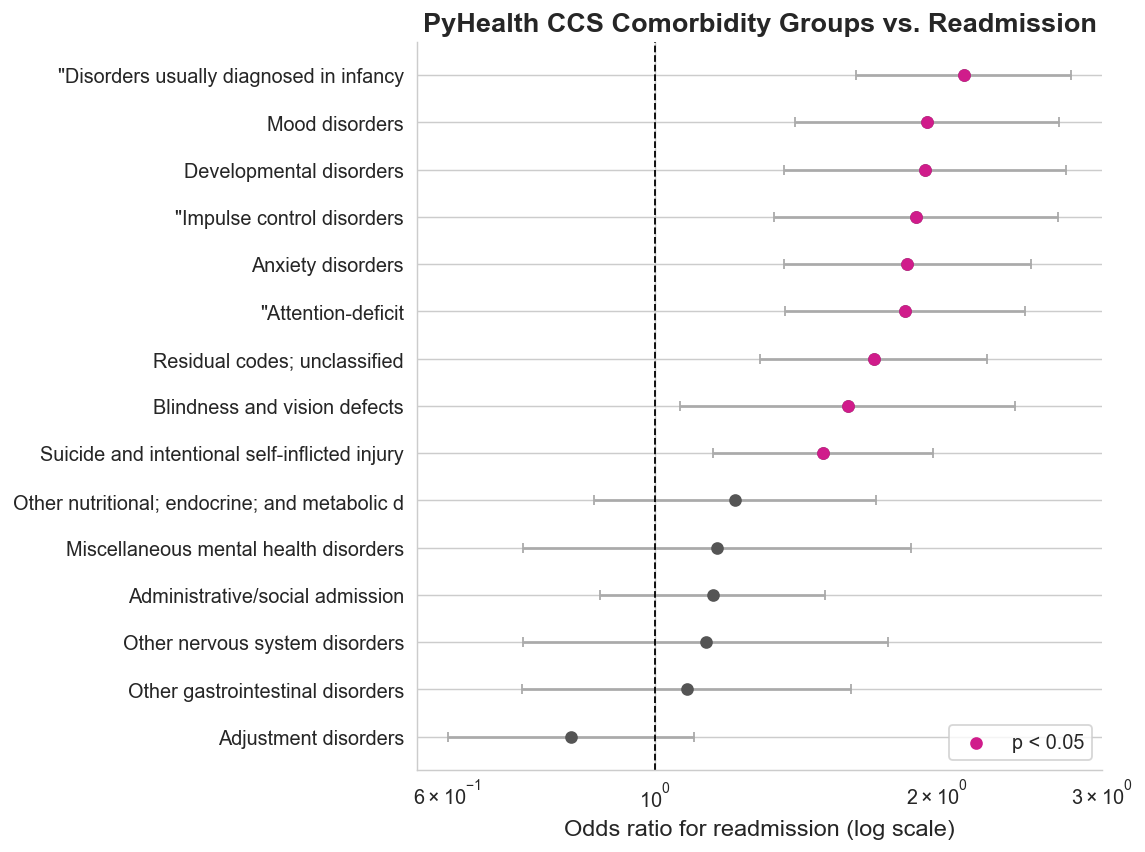


Incremental predictive value (10-fold OOF logistic AUC):
  Base (demographic + clinical)      AUC = 0.548
  Base + hand-built DSM-5 flags      AUC = 0.660
  Base + PyHealth CCS features       AUC = 0.696
  Base + DSM-5 + CCS                 AUC = 0.701


In [7]:
# ── B4: CCS readmission associations + comparison vs DSM-5 flags ──────────────
from statsmodels.stats.contingency_tables import Table2x2
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

y_b = ccs_features['readmitted'].values

# (a) Univariate odds ratios for each top CCS category
rows = []
for cat, col in zip(top_ccs, ccs_feature_cols):
    x = ccs_features[col].values
    a = int(((x == 1) & (y_b == 1)).sum()); b = int(((x == 1) & (y_b == 0)).sum())
    c = int(((x == 0) & (y_b == 1)).sum()); d = int(((x == 0) & (y_b == 0)).sum())
    tbl = Table2x2(np.array([[a + 0.5, b + 0.5], [c + 0.5, d + 0.5]]))  # Haldane correction
    rate_in  = a / (a + b) if (a + b) else np.nan
    rate_out = c / (c + d) if (c + d) else np.nan
    rows.append({'CCS category': cat[:45], 'N exposed': a + b,
                 'Readmit% (exposed)': rate_in * 100, 'Readmit% (unexposed)': rate_out * 100,
                 'OR': tbl.oddsratio, 'OR_lo': tbl.oddsratio_confint()[0],
                 'OR_hi': tbl.oddsratio_confint()[1], 'p': tbl.oddsratio_pvalue()})
ccs_assoc = pd.DataFrame(rows).sort_values('OR', ascending=False).reset_index(drop=True)
ccs_assoc.to_csv('figures/PyHealth_CCS_associations.csv', index=False)
print('Univariate readmission association by CCS category (Haldane-corrected ORs):')
print(ccs_assoc.round(3).to_string(index=False))

# Forest plot of CCS odds ratios
fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(ccs_assoc))))
ypos = np.arange(len(ccs_assoc))[::-1]
sig = ccs_assoc['p'] < 0.05
ax.errorbar(ccs_assoc['OR'], ypos,
            xerr=[ccs_assoc['OR'] - ccs_assoc['OR_lo'], ccs_assoc['OR_hi'] - ccs_assoc['OR']],
            fmt='o', color='#555', ecolor='#aaa', capsize=3, zorder=2)
ax.scatter(ccs_assoc.loc[sig, 'OR'], ypos[sig.values], color='#d01c8b', zorder=3,
           label='p < 0.05')
ax.axvline(1.0, color='k', ls='--', lw=1)
ax.set_yticks(ypos); ax.set_yticklabels(ccs_assoc['CCS category'])
ax.set_xscale('log'); ax.set_xlabel('Odds ratio for readmission (log scale)')
ax.set_title('PyHealth CCS Comorbidity Groups vs. Readmission', fontweight='bold')
ax.legend(loc='lower right')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/PyHealth_CCS_forest.png'); plt.show()

# (b) Incremental value: does standardized CCS encoding add signal vs hand-built flags?
base_cols = ['age', 'gender_male', 'insurance_public', 'ace_score', 'had_restraints',
             'csrss_any', 'los_days']
dsm5_cols = [c for c in CATEGORY_FLAGS]  # hand-built DSM-5 flags
base_df = df.copy()
base_df['ace_score'] = base_df['ace_score'].fillna(base_df['ace_score'].median())
base_df['los_days']  = base_df['los_days'].fillna(base_df['los_days'].median())

def oof_auc(Xcols_frame):
    Xv = Xcols_frame.values.astype(float)
    lr = LogisticRegression(max_iter=2000, class_weight='balanced')
    p = cross_val_predict(lr, Xv, y_b, cv=cv, method='predict_proba')[:, 1]
    return roc_auc_score(y_b, p)

feature_sets = {
    'Base (demographic + clinical)': base_df[base_cols],
    'Base + hand-built DSM-5 flags': pd.concat([base_df[base_cols], base_df[dsm5_cols]], axis=1),
    'Base + PyHealth CCS features':  pd.concat([base_df[base_cols].reset_index(drop=True),
                                                ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
    'Base + DSM-5 + CCS':            pd.concat([base_df[base_cols].reset_index(drop=True),
                                                base_df[dsm5_cols].reset_index(drop=True),
                                                ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
}
print('\nIncremental predictive value (10-fold OOF logistic AUC):')
for name, frame in feature_sets.items():
    print(f"  {name:<34} AUC = {oof_auc(frame):.3f}")

## Part C — Advanced statistical modeling

All analyses below operate on the **10-fold out-of-fold predictions** computed in Part A (`MODELS = {Logistic Regression, Random Forest, CatBoost}`), so performance, calibration, and fairness are assessed on held-out predictions rather than in-sample fits.

### C1 — Bootstrap 95% confidence intervals for AUC-ROC and AUC-PR

Discrimination point estimates are accompanied by stratified bootstrap percentile CIs (B = 2,000), which is essential here given only 246 events.

Bootstrap 95% CIs (B=2,000, stratified):
                     AUC-ROC  ROC 2.5%  ROC 97.5%  AUC-PR  PR 2.5%  PR 97.5%
Model                                                                       
Logistic Regression    0.667     0.633      0.704   0.162    0.143     0.191
Random Forest          0.686     0.653      0.720   0.171    0.149     0.202
CatBoost               0.662     0.625      0.698   0.164    0.143     0.196


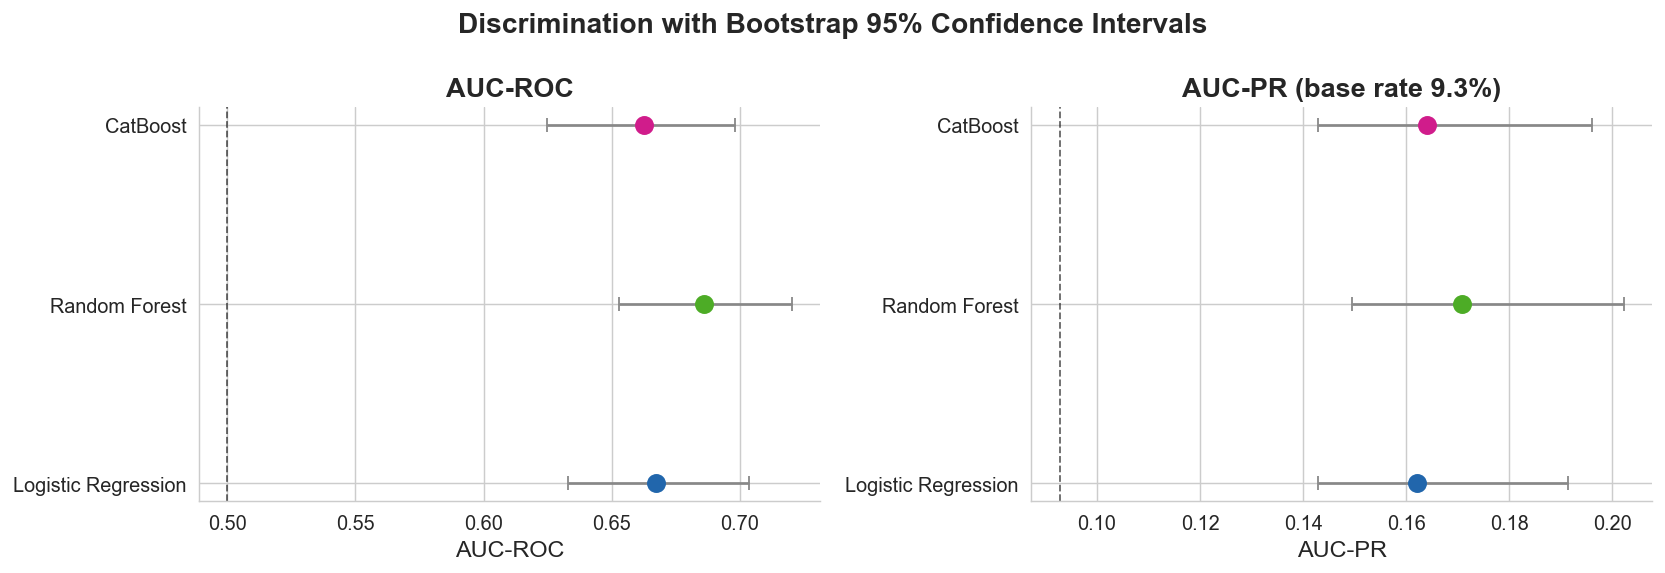

✓ Saved → figures/AdvStats_bootstrap_CIs.png


In [8]:
# ── C1: Bootstrap 95% CIs for AUC-ROC and AUC-PR ──────────────────────────────
def stratified_bootstrap_ci(y_true, y_prob, metric_fn, B=2000, seed=RNG_SEED):
    """Stratified (by class) bootstrap percentile CI for a probability metric."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    idx_pos = np.where(y_true == 1)[0]
    idx_neg = np.where(y_true == 0)[0]
    brng = np.random.default_rng(seed)
    stats_b = np.empty(B)
    for b in range(B):
        sp = brng.choice(idx_pos, size=len(idx_pos), replace=True)
        sn = brng.choice(idx_neg, size=len(idx_neg), replace=True)
        s = np.concatenate([sp, sn])
        stats_b[b] = metric_fn(y_true[s], y_prob[s])
    point = metric_fn(y_true, y_prob)
    lo, hi = np.percentile(stats_b, [2.5, 97.5])
    return point, lo, hi

ci_rows = []
for name, probs in MODELS.items():
    auc, auc_lo, auc_hi = stratified_bootstrap_ci(y_ml, probs, roc_auc_score)
    ap,  ap_lo,  ap_hi  = stratified_bootstrap_ci(y_ml, probs, average_precision_score)
    ci_rows.append({'Model': name,
                    'AUC-ROC': auc, 'ROC 2.5%': auc_lo, 'ROC 97.5%': auc_hi,
                    'AUC-PR': ap, 'PR 2.5%': ap_lo, 'PR 97.5%': ap_hi})
ci_df = pd.DataFrame(ci_rows).set_index('Model')
ci_df.to_csv('figures/AdvStats_bootstrap_CIs.csv')
print('Bootstrap 95% CIs (B=2,000, stratified):')
print(ci_df.round(3).to_string())

# Visualize AUC-ROC and AUC-PR with CIs
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metric, lo, hi, title) in zip(
        axes, [('AUC-ROC', 'ROC 2.5%', 'ROC 97.5%', 'AUC-ROC'),
               ('AUC-PR', 'PR 2.5%', 'PR 97.5%', 'AUC-PR (base rate 9.3%)')]):
    ypos = np.arange(len(ci_df))
    pts = ci_df[metric].values
    err = np.vstack([pts - ci_df[lo].values, ci_df[hi].values - pts])
    cols = [MODEL_COLORS[m] for m in ci_df.index]
    ax.errorbar(pts, ypos, xerr=err, fmt='o', capsize=4, color='#444', ecolor='#888')
    for yp, p, col in zip(ypos, pts, cols):
        ax.scatter([p], [yp], color=col, s=90, zorder=3)
    ax.set_yticks(ypos); ax.set_yticklabels(ci_df.index)
    ax.set_xlabel(metric); ax.set_title(title, fontweight='bold')
    if metric == 'AUC-ROC':
        ax.axvline(0.5, color='k', ls='--', lw=1, alpha=0.6)
    else:
        ax.axvline(y_ml.mean(), color='k', ls='--', lw=1, alpha=0.6)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.suptitle('Discrimination with Bootstrap 95% Confidence Intervals', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/AdvStats_bootstrap_CIs.png'); plt.show()
print('✓ Saved → figures/AdvStats_bootstrap_CIs.png')

### C2 — Calibration metrics + recalibration

Beyond the reliability diagrams in the main analysis, we quantify calibration with the **Brier score**, **Expected Calibration Error (ECE, 10 equal-width bins)**, and the **Hosmer–Lemeshow** goodness-of-fit test (10 risk deciles). We then apply **Platt (sigmoid)** and **isotonic** recalibration, fit with internal cross-validation on the held-out predictions, and report metrics before vs. after.

Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):
              Model Calibration  Brier    ECE   HL_chi2   HL_p    AUC
Logistic Regression         Raw 0.0825 0.0096   10.8322 0.2114 0.6674
Logistic Regression       Platt 0.0822 0.0081   10.1317 0.2559 0.6575
Logistic Regression    Isotonic 0.0822 0.0092   30.9762 0.0001 0.6322
      Random Forest         Raw 0.1787 0.3026 1115.4697 0.0000 0.6859
      Random Forest       Platt 0.0815 0.0047   11.2869 0.1860 0.6793
      Random Forest    Isotonic 0.0815 0.0015   22.9130 0.0035 0.6671
           CatBoost         Raw 0.1493 0.1935  863.2255 0.0000 0.6625
           CatBoost       Platt 0.0820 0.0057    9.1576 0.3292 0.6563
           CatBoost    Isotonic 0.0822 0.0053   12.3413 0.1366 0.6443


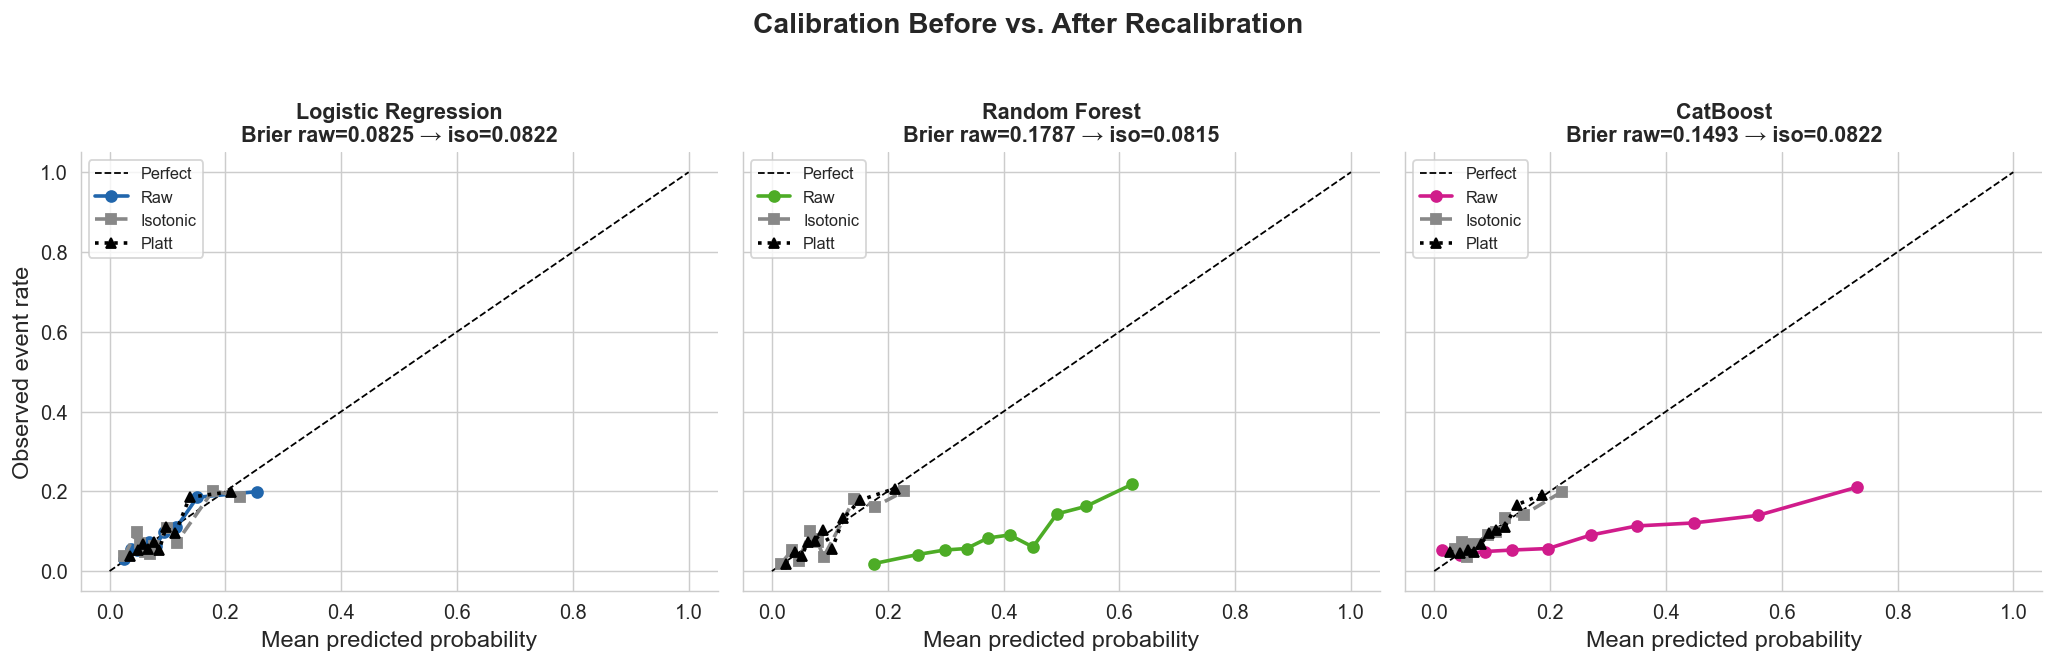

✓ Saved → figures/AdvStats_recalibration.png


In [9]:
# ── C2: Calibration metrics + Platt/isotonic recalibration ────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold

def expected_calibration_error(y_true, y_prob, n_bins=10):
    """ECE with equal-width bins."""
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(y_prob, bins[1:-1])
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum() == 0:
            continue
        ece += (m.mean()) * abs(y_true[m].mean() - y_prob[m].mean())
    return ece

def hosmer_lemeshow(y_true, y_prob, g=10):
    """Hosmer-Lemeshow chi-square statistic and p-value (risk deciles)."""
    order = np.argsort(y_prob)
    yt = np.asarray(y_true)[order]; yp = np.asarray(y_prob)[order]
    groups = np.array_split(np.arange(len(yp)), g)
    hl = 0.0
    for grp in groups:
        if len(grp) == 0:
            continue
        obs = yt[grp].sum(); exp = yp[grp].sum()
        n = len(grp)
        if 0 < exp < n:
            hl += (obs - exp) ** 2 / (exp * (1 - exp / n))
    dof = g - 2
    p = 1 - stats.chi2.cdf(hl, dof)
    return hl, p

def recalibrate(y_true, y_prob, method, n_splits=5, seed=RNG_SEED):
    """Return CV-honest recalibrated probabilities (Platt or isotonic)."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    out = np.zeros_like(y_prob, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    eps = 1e-6
    for tr, te in kf.split(y_prob):
        if method == 'platt':
            z_tr = np.log(np.clip(y_prob[tr], eps, 1 - eps) / (1 - np.clip(y_prob[tr], eps, 1 - eps)))
            z_te = np.log(np.clip(y_prob[te], eps, 1 - eps) / (1 - np.clip(y_prob[te], eps, 1 - eps)))
            lr = LogisticRegression().fit(z_tr.reshape(-1, 1), y_true[tr])
            out[te] = lr.predict_proba(z_te.reshape(-1, 1))[:, 1]
        else:  # isotonic
            ir = IsotonicRegression(out_of_bounds='clip').fit(y_prob[tr], y_true[tr])
            out[te] = ir.predict(y_prob[te])
    return out

cal_rows = []
recal_store = {}
for name, probs in MODELS.items():
    for label, p in [('Raw', probs),
                     ('Platt', recalibrate(y_ml, probs, 'platt')),
                     ('Isotonic', recalibrate(y_ml, probs, 'isotonic'))]:
        hl, hl_p = hosmer_lemeshow(y_ml, p)
        cal_rows.append({'Model': name, 'Calibration': label,
                         'Brier': brier_score_loss(y_ml, p),
                         'ECE': expected_calibration_error(y_ml, p),
                         'HL_chi2': hl, 'HL_p': hl_p,
                         'AUC': roc_auc_score(y_ml, p)})
        recal_store[(name, label)] = p
cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv('figures/AdvStats_calibration_metrics.csv', index=False)
print('Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):')
print(cal_df.round(4).to_string(index=False))

# Reliability diagrams: raw vs isotonic per model
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, probs) in zip(axes, MODELS.items()):
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect')
    for label, style in [('Raw', dict(marker='o', ls='-', color=MODEL_COLORS[name])),
                         ('Isotonic', dict(marker='s', ls='--', color='#888')),
                         ('Platt', dict(marker='^', ls=':', color='#000'))]:
        p = recal_store[(name, label)]
        frac, mean_pred = calibration_curve(y_ml, p, n_bins=10, strategy='quantile')
        ax.plot(mean_pred, frac, lw=2, markersize=6, label=label, **style)
    b_raw = brier_score_loss(y_ml, recal_store[(name, 'Raw')])
    b_iso = brier_score_loss(y_ml, recal_store[(name, 'Isotonic')])
    ax.set_title(f'{name}\nBrier raw={b_raw:.4f} → iso={b_iso:.4f}', fontweight='bold', fontsize=12)
    ax.set_xlabel('Mean predicted probability')
    ax.legend(fontsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('Observed event rate')
plt.suptitle('Calibration Before vs. After Recalibration', fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig('figures/AdvStats_recalibration.png'); plt.show()
print('✓ Saved → figures/AdvStats_recalibration.png')

### C3 — Formal fairness / equity metrics

Building on the subgroup-AUC analysis in the main notebook, we report a full equity panel for the best-discriminating model across **sex, insurance, age, and ACE strata**: subgroup AUC with bootstrap CIs, calibration-in-the-group, and — at a single global operating threshold (Youden's *J*) — sensitivity (TPR), false-positive rate, false-negative rate, PPV, and alert rate. We then summarize **equalized-odds gaps** (max |ΔTPR|, |ΔFPR|), **demographic-parity differences** (|Δ alert rate|), and **AUC gaps** for each protected-attribute pairing.

Primary fairness model: Random Forest | global threshold (Youden J) = 0.474

Equity panel — Random Forest @ threshold 0.474:
                        N  Events  Event rate  Mean pred    AUC  AUC_lo  AUC_hi    TPR    FPR    FNR    PPV  Alert rate  Calib ratio
Male               1369.0   134.0       0.098      0.405  0.705   0.661   0.748  0.627  0.291  0.373  0.190       0.324        4.140
Female             1283.0   112.0       0.087      0.385  0.661   0.611   0.711  0.491  0.235  0.509  0.167       0.257        4.408
Public insurance   1589.0   155.0       0.098      0.396  0.687   0.643   0.726  0.568  0.265  0.432  0.188       0.295        4.061
Private insurance  1063.0    91.0       0.086      0.394  0.683   0.630   0.735  0.560  0.261  0.440  0.167       0.287        4.605
Age <=9            1089.0   118.0       0.108      0.415  0.710   0.658   0.756  0.695  0.333  0.305  0.202       0.372        3.831
Age >=10           1563.0   128.0       0.082      0.382  0.652   0.602   0.6

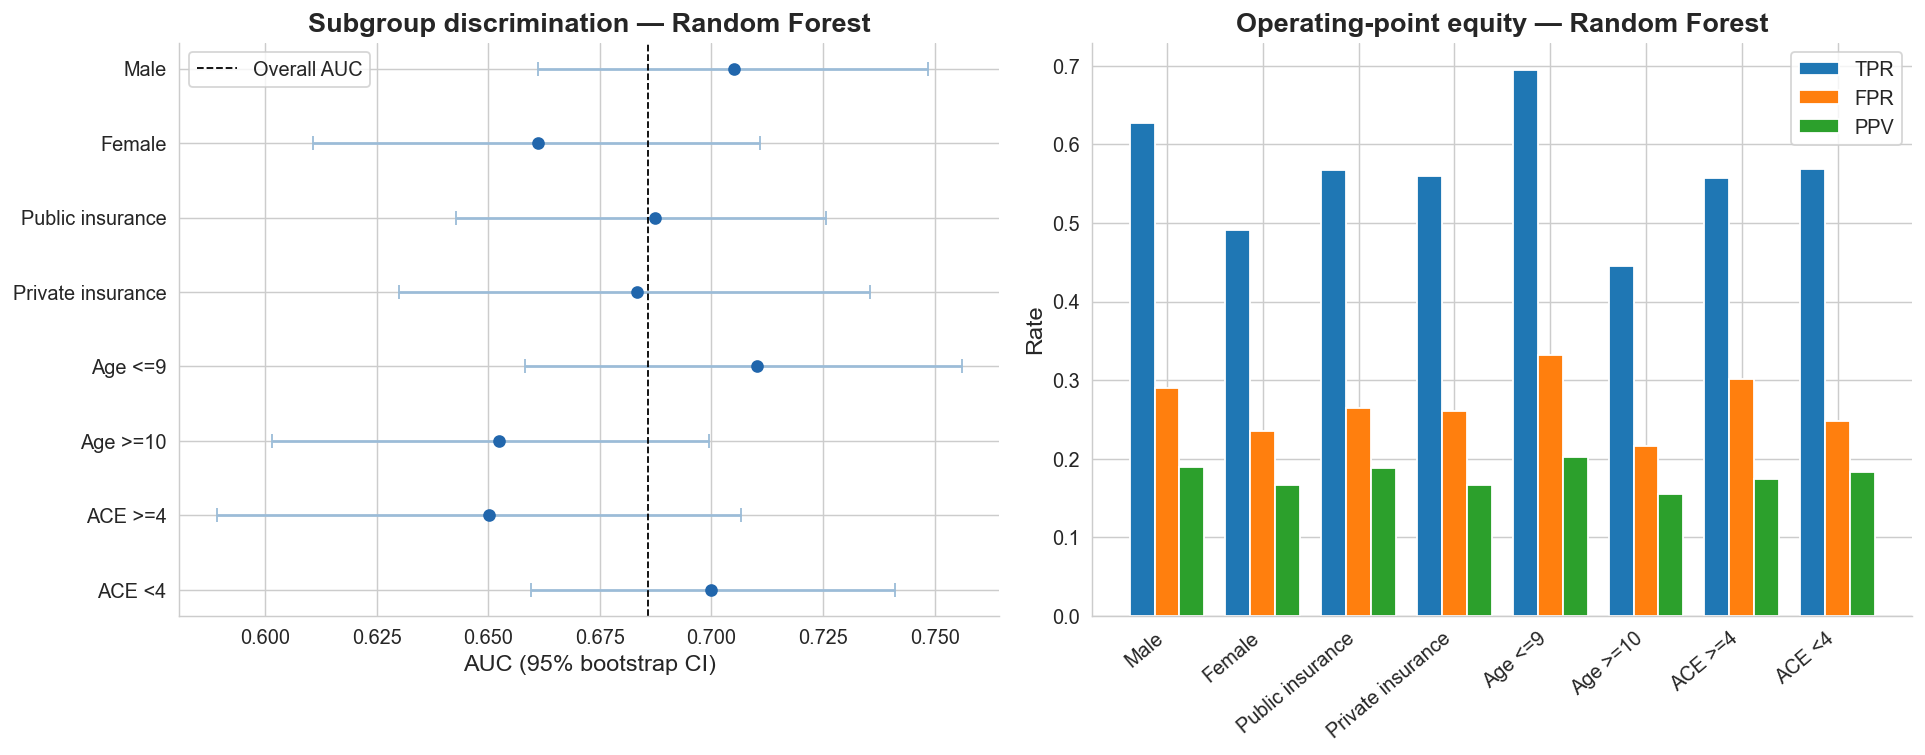

✓ Saved → figures/AdvStats_fairness.png


In [10]:
# ── C3: Fairness / equity metrics across protected subgroups ──────────────────
# Use the best-discriminating model (by overall AUC) and a single global threshold.
best_name = max(MODELS, key=lambda n: roc_auc_score(y_ml, MODELS[n]))
best_probs = MODELS[best_name]
fpr_g, tpr_g, thr_g = roc_curve(y_ml, best_probs)
thr_opt = thr_g[np.argmax(tpr_g - fpr_g)]   # Youden's J
print(f"Primary fairness model: {best_name} | global threshold (Youden J) = {thr_opt:.3f}")

mu = model_df_unscaled  # unscaled values for honest subgroup definitions
subgroups = {
    'Male': mu['gender_male'].values == 1,           'Female': mu['gender_male'].values == 0,
    'Public insurance': mu['insurance_public'].values == 1,
    'Private insurance': mu['insurance_public'].values == 0,
    'Age <=9': mu['age'].values <= 9,                'Age >=10': mu['age'].values >= 10,
    'ACE >=4': mu['ace_score'].values >= 4,          'ACE <4': mu['ace_score'].values < 4,
}

def subgroup_panel(mask, probs, thr):
    yt = y_ml[mask]; pp = probs[mask]; pred = (pp >= thr).astype(int)
    out = {'N': int(mask.sum()), 'Events': int(yt.sum()),
           'Event rate': yt.mean(), 'Mean pred': pp.mean()}
    # AUC + bootstrap CI (needs both classes, >=5 each)
    if yt.sum() >= 5 and (yt == 0).sum() >= 5:
        auc, lo, hi = stratified_bootstrap_ci(yt, pp, roc_auc_score, B=1000)
        out.update({'AUC': auc, 'AUC_lo': lo, 'AUC_hi': hi})
    else:
        out.update({'AUC': np.nan, 'AUC_lo': np.nan, 'AUC_hi': np.nan})
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    out['TPR'] = tp / (tp + fn) if (tp + fn) else np.nan      # sensitivity
    out['FPR'] = fp / (fp + tn) if (fp + tn) else np.nan
    out['FNR'] = fn / (fn + tp) if (fn + tp) else np.nan
    out['PPV'] = tp / (tp + fp) if (tp + fp) else np.nan
    out['Alert rate'] = pred.mean()                            # demographic-parity component
    out['Calib ratio'] = (pp.mean() / yt.mean()) if yt.mean() else np.nan
    return out

fair_df = pd.DataFrame({sg: subgroup_panel(m, best_probs, thr_opt)
                        for sg, m in subgroups.items()}).T
fair_df.to_csv('figures/AdvStats_fairness_subgroups.csv')
print(f"\nEquity panel — {best_name} @ threshold {thr_opt:.3f}:")
print(fair_df.round(3).to_string())

# Disparity summary per protected-attribute pairing
pairings = {'Sex (M vs F)': ('Male', 'Female'),
            'Insurance (Public vs Private)': ('Public insurance', 'Private insurance'),
            'Age (<=9 vs >=10)': ('Age <=9', 'Age >=10'),
            'ACE (>=4 vs <4)': ('ACE >=4', 'ACE <4')}
disp_rows = []
for label, (a, b) in pairings.items():
    ra, rb = fair_df.loc[a], fair_df.loc[b]
    disp_rows.append({
        'Pairing': label,
        'AUC gap': abs(ra['AUC'] - rb['AUC']),
        'Equalized-odds gap (max|dTPR|,|dFPR|)': max(abs(ra['TPR'] - rb['TPR']), abs(ra['FPR'] - rb['FPR'])),
        'Demographic-parity diff (|d alert|)': abs(ra['Alert rate'] - rb['Alert rate']),
        'FNR gap': abs(ra['FNR'] - rb['FNR']),
    })
disp_df = pd.DataFrame(disp_rows).set_index('Pairing')
disp_df.to_csv('figures/AdvStats_fairness_disparities.csv')
print('\nDisparity summary (0 = parity; larger = more inequitable):')
print(disp_df.round(3).to_string())

# Visualize: subgroup AUC with CIs + TPR/FPR/PPV bars
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = list(subgroups.keys())
ypos = np.arange(len(order))[::-1]
auc_pt = fair_df.loc[order, 'AUC'].values.astype(float)
err = np.vstack([auc_pt - fair_df.loc[order, 'AUC_lo'].values.astype(float),
                 fair_df.loc[order, 'AUC_hi'].values.astype(float) - auc_pt])
axes[0].errorbar(auc_pt, ypos, xerr=err, fmt='o', capsize=4, color='#2166ac', ecolor='#9bbcd8')
axes[0].axvline(roc_auc_score(y_ml, best_probs), color='k', ls='--', lw=1, label='Overall AUC')
axes[0].set_yticks(ypos); axes[0].set_yticklabels(order)
axes[0].set_xlabel('AUC (95% bootstrap CI)')
axes[0].set_title(f'Subgroup discrimination — {best_name}', fontweight='bold')
axes[0].legend()
for sp in ('top', 'right'):
    axes[0].spines[sp].set_visible(False)

metrics_bar = ['TPR', 'FPR', 'PPV']
xb = np.arange(len(order)); w = 0.26
for k, met in enumerate(metrics_bar):
    axes[1].bar(xb + (k - 1) * w, fair_df.loc[order, met].values.astype(float), w, label=met)
axes[1].set_xticks(xb); axes[1].set_xticklabels(order, rotation=40, ha='right')
axes[1].set_ylabel('Rate'); axes[1].set_title(f'Operating-point equity — {best_name}', fontweight='bold')
axes[1].legend()
for sp in ('top', 'right'):
    axes[1].spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_fairness.png'); plt.show()
print('✓ Saved → figures/AdvStats_fairness.png')

### C4 — Optimism-corrected validation

In-sample ("apparent") AUC is optimistically biased, especially with 246 events and flexible models. We quantify and correct this two ways: (1) the **Harrell–Steyerberg bootstrap optimism correction** (fit on each bootstrap, score on bootstrap vs. original) applied uniformly to all three models, and (2) **nested cross-validation** (5 outer × 3 inner folds with a small hyperparameter grid) for the ML models, which reflects honest performance once tuning is accounted for. We contrast these with the apparent and 10-fold OOF estimates.

Logistic Regression    apparent=0.714  optimism=0.030  corrected=0.684  OOF=0.667
Random Forest          apparent=0.844  optimism=0.097  corrected=0.748  OOF=0.686
CatBoost               apparent=0.913  optimism=0.112  corrected=0.800  OOF=0.662

Nested-CV AUC — Random Forest: 0.676 | CatBoost: 0.691

Validation summary:
                     Apparent AUC  Optimism  Bootstrap-corrected AUC  10-fold OOF AUC  Nested-CV AUC
Model                                                                                               
Logistic Regression         0.714     0.030                    0.684            0.667            NaN
Random Forest               0.844     0.097                    0.748            0.686          0.676
CatBoost                    0.913     0.112                    0.800            0.662          0.691


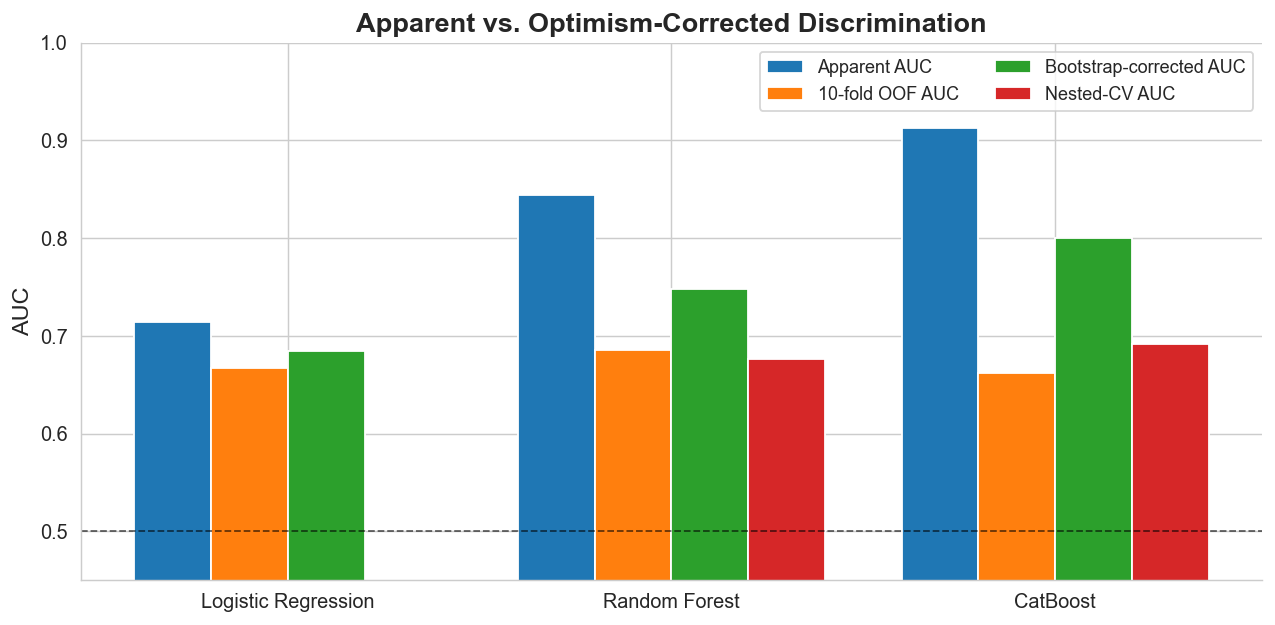

✓ Saved → figures/AdvStats_optimism_validation.png


In [11]:
# ── C4: Optimism-corrected validation (bootstrap + nested CV) ─────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score

# Model factories return a fresh fitted estimator with a predict_proba interface
def fit_lr(Xtr, ytr):
    return LogisticRegression(max_iter=2000, class_weight='balanced').fit(Xtr, ytr)
def fit_rf(Xtr, ytr):
    return RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=10,
                                  class_weight='balanced', random_state=RNG_SEED,
                                  n_jobs=-1).fit(Xtr, ytr)
def fit_cb(Xtr, ytr):
    m = CatBoostClassifier(iterations=250, depth=4, learning_rate=0.05,
                           auto_class_weights='Balanced', random_seed=RNG_SEED, verbose=0)
    return m.fit(Xtr, ytr)

FITTERS = {'Logistic Regression': fit_lr, 'Random Forest': fit_rf, 'CatBoost': fit_cb}
B_OPT = {'Logistic Regression': 200, 'Random Forest': 150, 'CatBoost': 100}

def bootstrap_optimism(fitter, X, y, B, seed=RNG_SEED):
    """Harrell-Steyerberg optimism correction for AUC."""
    full = fitter(X, y)
    apparent = roc_auc_score(y, full.predict_proba(X)[:, 1])
    brng = np.random.default_rng(seed)
    n = len(y); opt = []
    for _ in range(B):
        idx = brng.integers(0, n, n)
        if y[idx].sum() < 2 or (y[idx] == 0).sum() < 2:
            continue
        mb = fitter(X[idx], y[idx])
        auc_boot = roc_auc_score(y[idx], mb.predict_proba(X[idx])[:, 1])
        auc_orig = roc_auc_score(y, mb.predict_proba(X)[:, 1])
        opt.append(auc_boot - auc_orig)
    optimism = float(np.mean(opt))
    return apparent, optimism, apparent - optimism

opt_rows = []
for name, fitter in FITTERS.items():
    app, optimism, corrected = bootstrap_optimism(fitter, X_ml, y_ml, B_OPT[name])
    oof = roc_auc_score(y_ml, MODELS[name])
    opt_rows.append({'Model': name, 'Apparent AUC': app, 'Optimism': optimism,
                     'Bootstrap-corrected AUC': corrected, '10-fold OOF AUC': oof})
    print(f"{name:<22} apparent={app:.3f}  optimism={optimism:.3f}  "
          f"corrected={corrected:.3f}  OOF={oof:.3f}")

# Nested CV (5 outer x 3 inner) for the ML models with a small grid
nested = {}
rf_grid = {'max_depth': [4, 6], 'min_samples_leaf': [10, 20]}
cb_grid = {'depth': [3, 4], 'learning_rate': [0.03, 0.05]}
nested['Random Forest'] = cross_val_score(
    GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                         random_state=RNG_SEED, n_jobs=-1),
                 rf_grid, cv=3, scoring='roc_auc'),
    X_ml, y_ml, cv=5, scoring='roc_auc').mean()
nested['CatBoost'] = cross_val_score(
    GridSearchCV(CatBoostClassifier(iterations=200, auto_class_weights='Balanced',
                                    random_seed=RNG_SEED, verbose=0),
                 cb_grid, cv=3, scoring='roc_auc'),
    X_ml, y_ml, cv=5, scoring='roc_auc').mean()
print(f"\nNested-CV AUC — Random Forest: {nested['Random Forest']:.3f} | "
      f"CatBoost: {nested['CatBoost']:.3f}")

opt_df = pd.DataFrame(opt_rows).set_index('Model')
opt_df['Nested-CV AUC'] = pd.Series(nested)
opt_df.to_csv('figures/AdvStats_optimism_validation.csv')
print('\nValidation summary:')
print(opt_df.round(3).to_string())

# Plot apparent vs honest estimates
fig, ax = plt.subplots(figsize=(10, 5))
cols_plot = ['Apparent AUC', '10-fold OOF AUC', 'Bootstrap-corrected AUC', 'Nested-CV AUC']
xb = np.arange(len(opt_df)); w = 0.2
for k, col in enumerate(cols_plot):
    ax.bar(xb + (k - 1.5) * w, opt_df[col].values.astype(float), w, label=col)
ax.axhline(0.5, color='k', ls='--', lw=1, alpha=0.6)
ax.set_xticks(xb); ax.set_xticklabels(opt_df.index)
ax.set_ylabel('AUC'); ax.set_ylim(0.45, 1.0)
ax.set_title('Apparent vs. Optimism-Corrected Discrimination', fontweight='bold')
ax.legend(fontsize=10, ncol=2)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_optimism_validation.png'); plt.show()
print('✓ Saved → figures/AdvStats_optimism_validation.png')

## Summary & saved artifacts

**Part B (PyHealth EHR coding).** `pyhealth.medcode` validated the cohort's raw ICD-10 codes against the official vocabulary, recovered standardized descriptions, and grouped codes into reproducible CCS comorbidity categories — a principled, externally-defined feature set that complements the hand-curated DSM-5 flags and lets us check how much predictive signal is encoding-dependent.

**Part C (advanced statistics).**
- **C1** Bootstrap 95% CIs make clear that, with only 246 events, the models' discrimination CIs overlap substantially.
- **C2** Brier/ECE/Hosmer–Lemeshow quantify calibration; Platt and isotonic recalibration are reported before vs. after.
- **C3** A full equity panel (subgroup AUC + CIs, calibration-in-group, TPR/FPR/FNR/PPV, equalized-odds gaps, demographic-parity differences) flags where performance differs across sex, insurance, age, and ACE strata.
- **C4** Apparent AUC is contrasted with 10-fold OOF, bootstrap optimism-corrected, and nested-CV estimates to expose over-optimism.

**Saved files** (in `./figures/`): `PyHealth_ICD_validation.csv`, `PyHealth_CCS_patient_features.csv`, `PyHealth_CCS_associations.csv`, `PyHealth_CCS_forest.png`, `AdvStats_bootstrap_CIs.{csv,png}`, `AdvStats_calibration_metrics.csv`, `AdvStats_recalibration.png`, `AdvStats_fairness_subgroups.csv`, `AdvStats_fairness_disparities.csv`, `AdvStats_fairness.png`, `AdvStats_optimism_validation.{csv,png}`.

> **Caveat.** This is a single-site, cross-sectional, single-visit cohort with a low event count; all estimates are exploratory and require external/temporal validation before any clinical use.